## Project 
139 data set

In [1]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
import scipy.stats as stats
from sklearn import preprocessing
from IPython.display import display
sns.set_theme(style="whitegrid")

In [2]:
filename_1 = "data/gateways.csv"
filename_2 = "data/readings.csv"
filename_3 = "data/units.csv"
def identify_outliers(a):
    lower = a.quantile(0.25) - 1.5 * stats.iqr(a)
    upper = a.quantile(0.75) + 1.5 * stats.iqr(a)
    
    return a[(a > upper) | (a < lower)]

In [ ]:
data_1 = pd.read_csv(filename_1, 
                   sep=';', index_col=13)
data_1.head(20)
#data_1.iloc[1999:2020] # id_unit from 2000 to end are NaN

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
gateway_id,,,,,,,,,,,,,
GW-01999,2024/05/14,2016-06-21,-6.24800,43,de:ba:41:f3:c9:99,v2.7.0,-67.0,38.60958,Andrade S.A.,GWX-100,763.0,Jeremy Sherman,218.108.94.86
GW-02000,2024-05-22,2022/06/04,-8.68316,111,c7:76:03:bd:72:03,v2.7.0,-73.5,40.39939,Tavares,NODE-7,NaN,Toralf Mentzel,114.107.184.6
GW-02001,12 Dec 2024,2017/05/29,-8.69767,39,b0:46:b5:c0:ce:69,v1.2.5,-65.2,38.70258,Pacheco,GWX-200,NaN,Prof. Cornelia Bolnbach B.A.,100.208.230.119
GW-02002,2024-11-28,2019/01/30,-7.21550,42,c1:1e:a9:70:b6:c3,v3.4.1,-69.0,39.55325,Speer,NODE-9,NaN,Ivan Leal,15.223.22.198
GW-02003,2025-01-11,"12/08/2019, 00:00:00",-8.99649,48,f7:67:09:c5:d1:e5,v2.7.0,-73.7,39.84780,Amorim,GWX-300,NaN,Elisabeth Seifert,187.35.83.218
GW-02004,2024/08/28,2022/09/22,-8.94349,48,de:79:e5:97:58:d6,v1.2.5,-79.9,39.96341,Koch-Moody,GWX-300,NaN,Isabela Barbosa,55.172.222.1
GW-02005,"08/15/2024, 00:00:00","09/22/2020, 00:00:00",-7.26141,35,59:5f:5a:17:28:4c,v3.4.1,-48.6,39.86669,Amorim,NODE-9,NaN,Matthew Torres,238.10.177.149
GW-02006,2024/11/18,2019/03/14,-8.17182,44,15:5f:d9:70:fe:0a,v2.7.0,-62.3,39.37855,Fritsch,NODE-9,NaN,Stephanie Allison,107.109.53.8
GW-02007,2024-06-13,2016-01-18,-6.65883,52,91:dc:69:36:ac:37,v2.7.0,-67.1,41.08669,Mills LLC,NODE-7,NaN,Larry Roberson,247.41.193.19


gateway_id - Textual - maybe change to numerical(remove GW from start)

seen_last - Time-series

install_date - Time-series

lon - Numerical(continuous)

idDeport - Discrete

macAddress - Textual ? - cant decide same as ip

versionFirmware - Categorical

signal_dbm - Numerical(continuous)

lat - Numerical(continuous)

Vendor - Categorical

hardware_model - Categorical

id_unit - Numerical(continuous) - change to discrete (all nums have .0) / from 2000 to end are NaN - problem? 

Technician - Categorical(nominal)

ipv4 - Textual ? - cant decide

In [5]:
data_2 = pd.read_csv(filename_2, 
                    sep='\t')
data_2.head(20)

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
0,U00078,24 Sep 2023,2.91072,17.08727,63.17362,10.42780,5.53225,24.90723,5.49963,0
1,U01922,2023-10-05,5.20071,14.68177,36.67755,8.84326,6.40699,26.62476,7.60072,1
2,U00548,2023-10-18,5.56161,44.22325,43.50675,8.03135,4.30464,26.39225,5.25673,0
3,U01551,21 Mar 2023,5.12227,21.50330,63.91073,7.86316,1.66650,22.98348,5.09449,1
4,U00298,04 Oct 2023,5.11036,29.84890,64.71004,9.78952,2.82960,33.75524,11.50507,0
5,U01522,12 Dec 2023,2.47593,NaN,63.34515,8.66470,5.10853,27.65622,5.79981,1
6,U00748,2023/04/23,6.60443,18.84023,40.67046,8.61937,NaN,25.53233,3.43388,1
7,U00565,2023/03/24,6.48482,26.42038,52.23038,8.45314,1.85331,26.09878,7.24156,0
8,U00588,"01/02/2023, 14:07:00",6.63109,NaN,60.44142,9.34893,3.28290,28.68901,16.55528,1
9,U01188,2023-03-17,4.51353,45.42224,57.41512,8.61459,2.45468,33.13947,8.77440,1


id_unit - Categorical(nominal) - maybe change to numerical(remove U from start because units table has numerical id)

cycle_ts - Time-series

currentMotor - Numerical(continuous)

dp_filter - Numerical(continuous)

oilTemperature - Numerical(continuous)

presure_reservoir - Numerical(continuous)

rmsVibration - Numerical(continuous)

Flowmeter - Numerical(continuous)
 
dischargeDewpoint - Numerical(continuous)

Failure - Categorical(Boolean)

In [6]:
data_3 = pd.read_csv(filename_3, 
                    sep=',',index_col=5
                    )
data_3.head(20)

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
id_unit,,,,,,
1,97,light,2022,7263.7,"09/23/2021, 00:00:00",GQ-0521-56531
2,81,heavy,2023,6053.4,2020-05-07,HN-5203-27688
3,56,light,2023,4921.4,2021/06/04,QC-5243-50182
4,53,3,2018,21803.6,25 Apr 2021,TC-5483-81500
5,54,normal,2020,15730.5,"08/13/2024, 00:00:00",XO-0640-55128
6,49,normal,2024,2672.6,07 Apr 2023,NL-5523-44373
7,54,normal,2017,26298.5,2021-12-02,GM-2661-34290
8,5,light,2019,17581.9,2015/05/15,DE-2078-95757
9,25,L,2022,9111.4,15 Jun 2018,MC-2132-88338


id_unit - Numerical

idDeport - Numerical

duty_class - Categorical - change category names (can see diff names for 1 category)

year_commision - Numerical - not sure its ok

service_hours - Numerical(Continuous)

overhaul_last - Time-series

serial_number - Textual

In [7]:
data_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16000 entries, GW-00000 to GW-15999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   seen_last        16000 non-null  object 
 1   install_date     16000 non-null  object 
 2   Lon              16000 non-null  float64
 3   idDepot          16000 non-null  int64  
 4   macAddress       16000 non-null  object 
 5   versionFirmware  16000 non-null  object 
 6   signal_dbm       16000 non-null  float64
 7   lat              16000 non-null  float64
 8   Vendor           16000 non-null  object 
 9   hardware_model   16000 non-null  object 
 10  id_unit          2000 non-null   float64
 11  Technician       16000 non-null  object 
 12  ipv4             16000 non-null  object 
dtypes: float64(4), int64(1), object(8)
memory usage: 1.7+ MB


id_unit from 2000 to end are NaN - problem?

In [8]:
data_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14052 entries, 0 to 14051
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_unit             14052 non-null  object 
 1   cycle_ts            14052 non-null  object 
 2   currentMotor        14052 non-null  float64
 3   dp_filter           13503 non-null  float64
 4   oilTemperature      14052 non-null  float64
 5   pressure_reservoir  14052 non-null  float64
 6   rmsVibration        13534 non-null  float64
 7   Flowmeter           14052 non-null  float64
 8   dischargeDewpoint   14052 non-null  float64
 9   Failure             14052 non-null  int64  
dtypes: float64(7), int64(1), object(2)
memory usage: 1.1+ MB


dp_filter and 13534 have NaN values - remove / replace

In [9]:
data_3.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 1 to 2000
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   idDepot          2000 non-null   int64  
 1   duty_class       2000 non-null   object 
 2   year_commission  2000 non-null   int64  
 3   serviceHours     1900 non-null   float64
 4   overhaul_last    2000 non-null   object 
 5   serial_number    2000 non-null   object 
dtypes: float64(1), int64(2), object(3)
memory usage: 109.4+ KB


serviceHours - NaN values remove / replace

In [10]:
data_1.describe(include='all')

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
count,16000,16000,16000.000000,16000.000000,16000,16000,16000.000000,16000.000000,16000,16000,2000.000000,16000,16000
unique,1600,9723,NaN,NaN,16000,3,NaN,NaN,38,5,NaN,120,16000
top,2024-08-05,2023-05-31,NaN,NaN,5a:bb:a2:f5:b8:9a,v1.2.5,NaN,NaN,Speer,NODE-9,NaN,Miguel Marques,240.30.225.100
freq,22,7,NaN,NaN,1,5359,NaN,NaN,810,3263,NaN,165,1
mean,NaN,NaN,-7.751588,58.854125,NaN,NaN,-70.170300,40.155156,NaN,NaN,1000.500000,NaN,NaN
std,NaN,NaN,0.891284,34.567290,NaN,NaN,10.006577,0.900882,NaN,NaN,577.494589,NaN,NaN
min,NaN,NaN,-9.299980,0.000000,NaN,NaN,-107.300000,38.600070,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,-8.524577,29.000000,NaN,NaN,-77.000000,39.373440,NaN,NaN,500.750000,NaN,NaN
50%,NaN,NaN,-7.758115,59.000000,NaN,NaN,-70.200000,40.163690,NaN,NaN,1000.500000,NaN,NaN
75%,NaN,NaN,-6.980605,89.000000,NaN,NaN,-63.400000,40.937605,NaN,NaN,1500.250000,NaN,NaN


In [11]:
data_2.describe(include='all')

,id_unit,cycle_ts,currentMotor,dp_filter,oilTemperature,pressure_reservoir,rmsVibration,Flowmeter,dischargeDewpoint,Failure
count,14052,14052,14052.000000,13503.000000,14052.000000,14052.000000,13534.000000,14052.000000,14052.000000,14052.000000
unique,2112,4579,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,U01347,13 Dec 2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,17,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,5.277158,24.073502,50.628361,8.698509,3.083622,27.925684,7.971619,0.118844
std,NaN,NaN,2.893927,11.434870,68.623763,0.601964,1.643651,4.007567,3.507052,0.323617
min,NaN,NaN,0.115880,7.081150,-999.000000,6.500000,0.500000,15.000000,-5.117820,0.000000
25%,NaN,NaN,3.731485,16.246110,46.753862,8.298048,1.936292,25.222520,5.666065,0.000000
50%,NaN,NaN,5.127835,21.249320,55.072740,8.696900,2.718050,27.936505,7.972520,0.000000
75%,NaN,NaN,6.643298,28.690820,63.030540,9.102232,3.830090,30.630375,10.308608,0.000000


In [12]:
data_3.describe(include='all')

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
count,2000.000000,2000,2000.000000,1900.000000,2000,2000
unique,NaN,20,NaN,NaN,1842,2000
top,NaN,L,NaN,NaN,"12/10/2021, 00:00:00",EA-4785-20447
freq,NaN,252,NaN,NaN,3,1
mean,54.737500,NaN,2020.343000,14588.644842,NaN,NaN
std,34.325074,NaN,2.547076,8953.209427,NaN,NaN
min,0.000000,NaN,2012.000000,1303.000000,NaN,NaN
25%,24.000000,NaN,2019.000000,8224.525000,NaN,NaN
50%,53.000000,NaN,2021.000000,12343.300000,NaN,NaN
75%,83.000000,NaN,2022.000000,18475.050000,NaN,NaN


## Short report: 

Data are distributed into 3 .csv files(**gateway**, **readings**, **units**). **gateway** file need ';' to separete data and **gateway_id** is used as index. **readings** need '\t' to separete data. **units** need ',' to separate data and **id_unit** is used as index. **readings** and **units** are related becauce readings is information about checkup of unit. Not sure but **gateway** has info about device which is used to checkup or install something on unit. Number of records: **gateway** - 16000; **readings** - 14052; **units** - 2000. **gateway** has 13 attirbutes(float64(4), int64(1), str(8)); **readings** has 10 attributes (float64(7), int64(1), str(2)); **units** has 6 attributes (float64(1), int64(2), str(3)). Problems in dataset (maybe for 1.2 too):

geteways: 
- Inconsistant naming of the attributes for example: seen_last, Lon, versionFirmware, Technician 
- gateway_id - bad format, shold be integer, not string
- seen_last	- not consistant time format
- install_date - not consistant time format
- id_unit	- only 2000 samples have it other 14000 have NaN; should be integer, not float

readings:
- Inconsistant naming of the attributes
- id_unit - wrong format, shold be integer, not string
- cycle_ts - not consistant time format
- dp_filter and rmsVibration have NaN values 
- oilTemperature - min is -999.000000, not logical, problem in data

units: 
- Inconsistant naming of the attributes
- duty_class has inconsistant naming of categories 20, should be 3 ['light', 'heavy', 'medium']
- overhaul_last - not consistant time format
- serviceHours - has 100 NaN values

## Important attributes(maybe):
**units**: duty_class; service_hours

**readings**: currentMotor; dp_filter; oilTemperature; pressure_reservoir; rmsVibration; Flowmeter; dischargeDewpoint; Failure

**gateways**: Lon; signal_dbm; hardware_model; lat; versionFirmware; Vendor

In [13]:
data_3.dropna().shape[0]

1900

In [14]:
data_3.isnull().sum()

idDepot              0
duty_class           0
year_commission      0
serviceHours       100
overhaul_last        0
serial_number        0
dtype: int64

In [15]:
data_3[data_3.isnull().any(axis=1)]

,idDepot,duty_class,year_commission,serviceHours,overhaul_last,serial_number
id_unit,,,,,,
66,86,light,2020,NaN,19 Apr 2021,WJ-1589-63660
76,1,2,2022,NaN,"09/30/2020, 00:00:00",BQ-8095-74652
130,84,heavy,2020,NaN,2017-02-15,RL-2537-51896
153,24,L,2021,NaN,28 May 2021,YW-4417-33641
162,74,2,2021,NaN,16 Oct 2016,LN-7120-15596
...,...,...,...,...,...,...
1932,8,L,2020,NaN,"11/09/2020, 00:00:00",EF-9953-30481
1968,44,1,2022,NaN,"03/04/2016, 00:00:00",CA-8817-92790
1994,16,1,2021,NaN,05 Aug 2024,PS-9327-19274


In [16]:
data_3.duty_class.unique()

array(['light', 'heavy', ' 3 ', 'normal', 'L', ' 1 ', 'med', '2', 'N',
       '1', ' heavy ', '3', ' med ', ' L ', ' light ', 'H', ' H ',
       ' normal ', ' N ', ' 2 '], dtype=object)

In [17]:
data_3['duty_class'] = (
    data_3['duty_class']
    .str.strip()
    .replace({
        '1': 'light',
        'L': 'light',
        'light': 'light',

        '2': 'medium',
        'med': 'medium',
        'N': 'medium',
        'normal': 'medium',

        '3': 'heavy',
        'H': 'heavy',
        'heavy': 'heavy'
    })
)

In [18]:
data_3.duty_class.unique()

array(['light', 'heavy', 'medium'], dtype=object)

In [19]:
data_3.groupby('duty_class').size()

duty_class
heavy     510
light     804
medium    686
dtype: int64

In [20]:
data_3.serviceHours.describe()

count     1900.000000
mean     14588.644842
std       8953.209427
min       1303.000000
25%       8224.525000
50%      12343.300000
75%      18475.050000
max      45000.000000
Name: serviceHours, dtype: float64

<Axes: xlabel='serviceHours', ylabel='duty_class'>

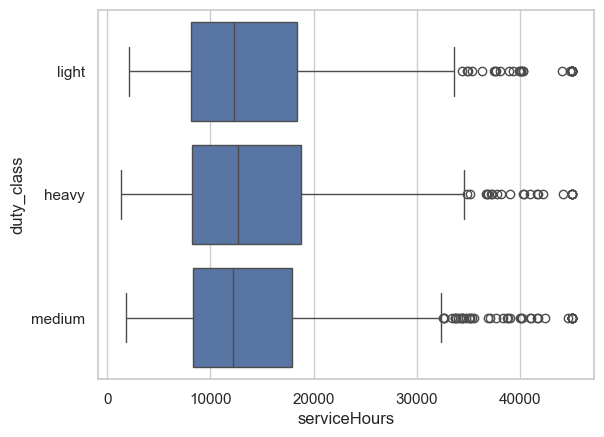

In [21]:
sns.boxplot(data=data_3, x="serviceHours", y="duty_class")

array([[<Axes: title={'center': 'idDepot'}>,
        <Axes: title={'center': 'year_commission'}>],
       [<Axes: title={'center': 'serviceHours'}>, <Axes: >]], dtype=object)

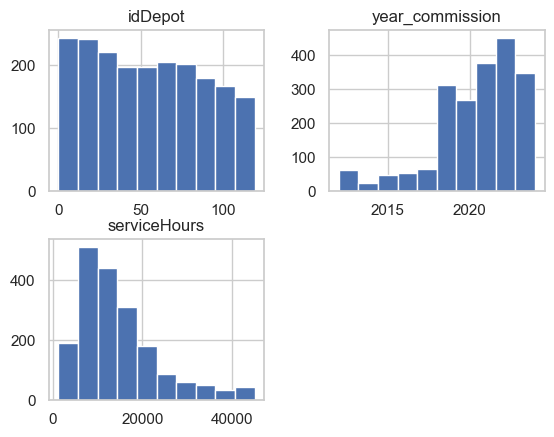

In [22]:
data_3.hist()

1.1.B - Analyza jednotlivych atributov

In [23]:
sensor_cols = ['currentMotor', 'dp_filter', 'oilTemperature', 'pressure_reservoir',
               'rmsVibration', 'Flowmeter', 'dischargeDewpoint']
# ciselne atributy su 7 senzorov + serviceHours (units) + signal_dbm (gateways)
attrs = [(data_2, c) for c in sensor_cols] + [(data_3, 'serviceHours'), (data_1, 'signal_dbm')]
# 10. atribut je kategoria duty_class (units), ta ide zvlast

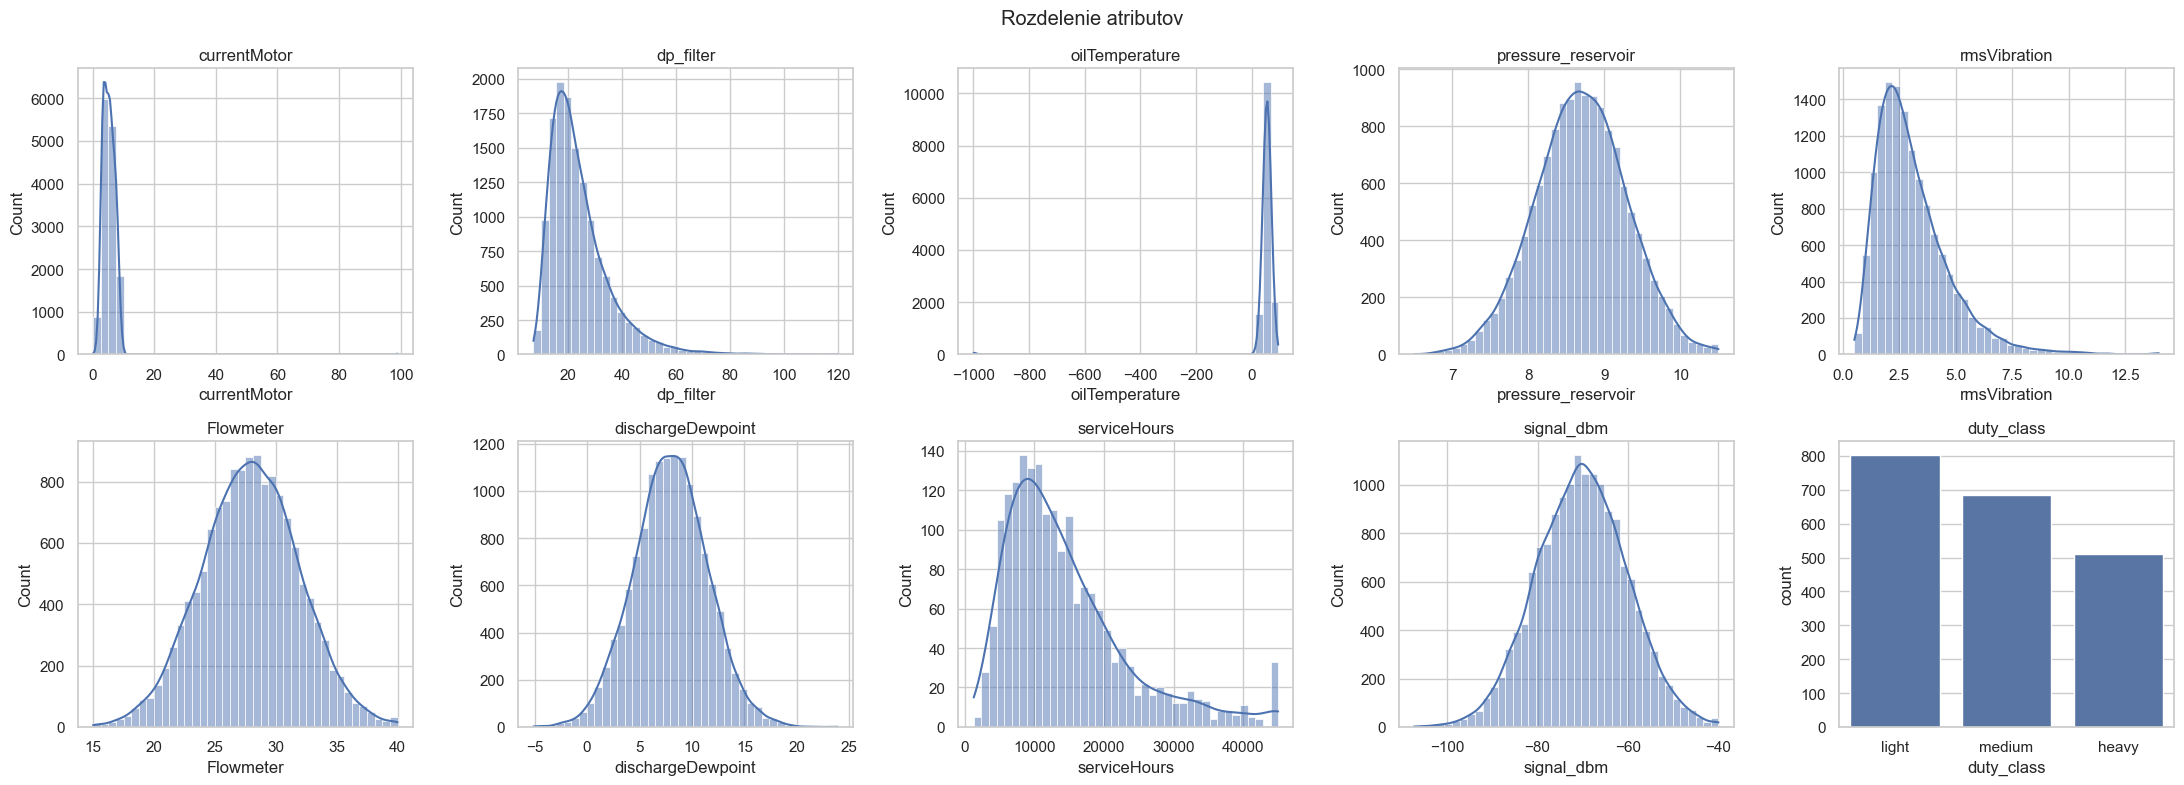

In [24]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.ravel()

for ax, (df_, c) in zip(axes, attrs):
    sns.histplot(df_[c].dropna(), bins=40, kde=True, ax=ax)
    ax.set_title(c)
    
sns.countplot(x='duty_class', data=data_3, order=['light', 'medium', 'heavy'], ax=axes[9])
axes[9].set_title('duty_class')
plt.suptitle('Rozdelenie atributov')
plt.tight_layout(); plt.show()

- currentMotor a oilTemperature maju hlavnu cast hodnot blizko pri sebe, ale osi su natiahnute kvoli osamotenym extremom (99 pri motore, -999 pri oleji), preto graf vyzera ako jediny stlpec,   asi sa jedna o chybne kody
- serviceHours ma stlpec pri 45 000, co vyzera ako strop (hodnoty su orezane na maximum).
- dp_filter, rmsVibration a serviceHours su pravostranne sikme (vacsina hodnot je nizko, dlhy chvost je doprava).
- pressure_reservoir, Flowmeter, dischargeDewpoint a signal_dbm maju zvonovity tvar, su priblizne normalne.
- duty_class nie je uplne vyvazena (light 804, medium 686, heavy 510), ale kazda trieda ma dost zaznamov.

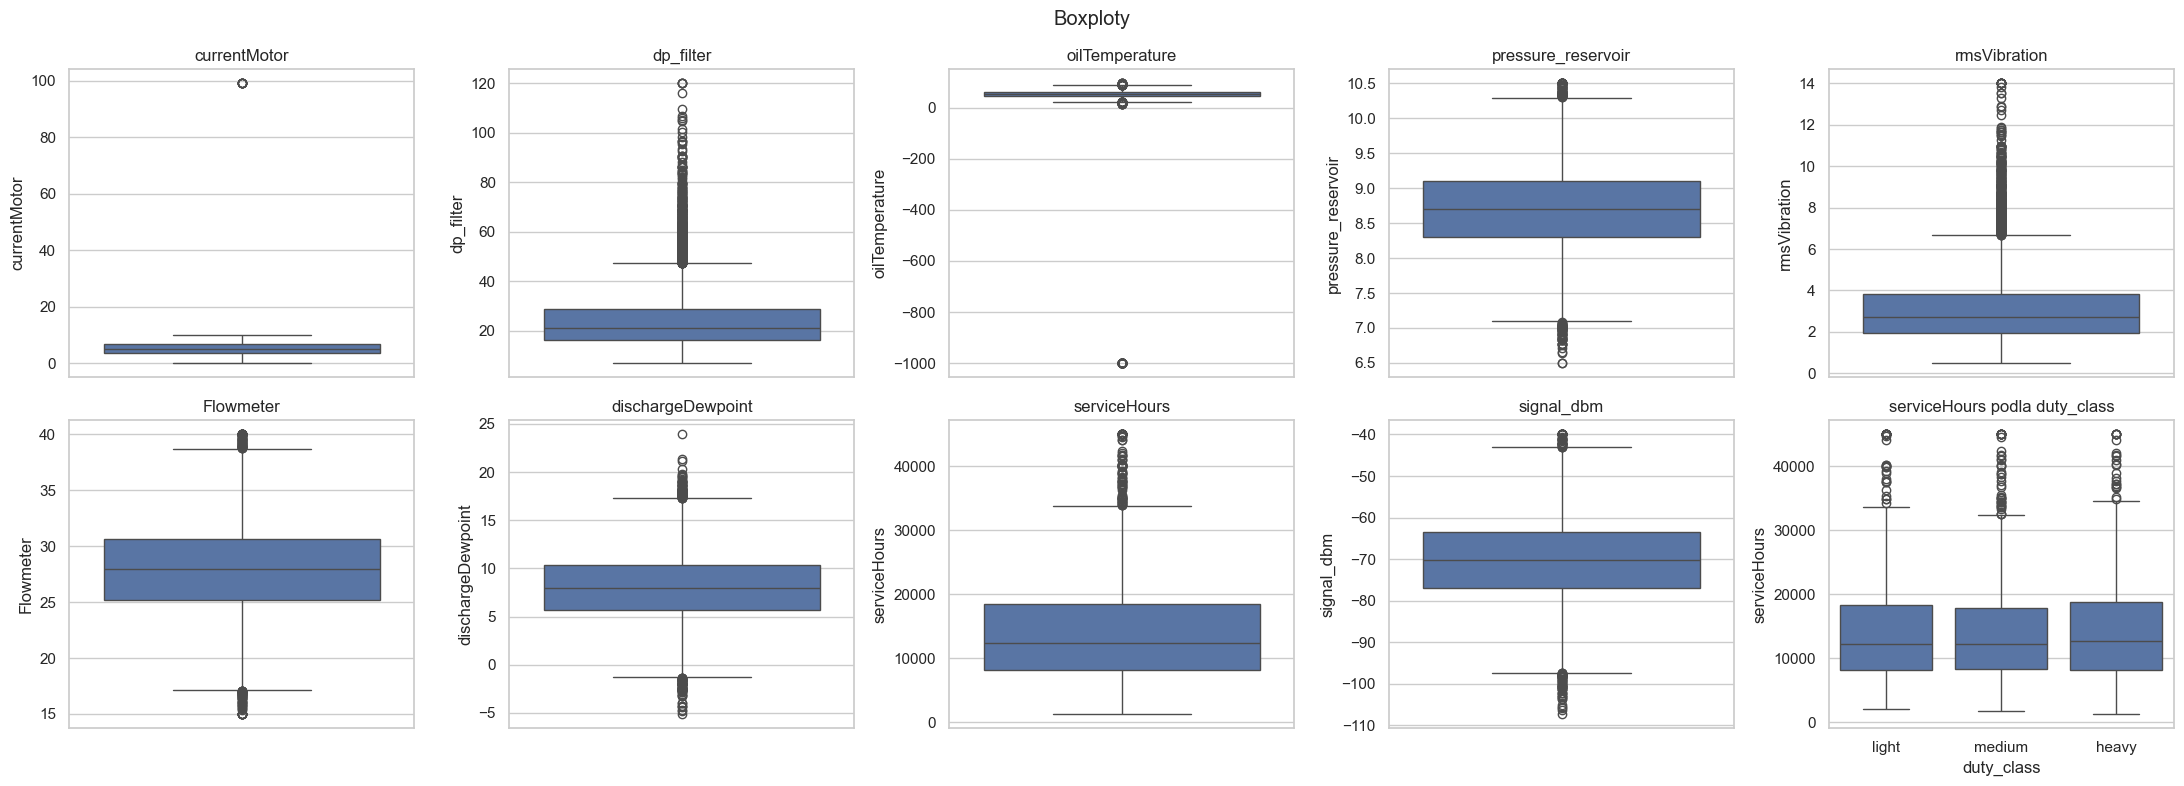

In [25]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.ravel()

for ax, (df_, c) in zip(axes, attrs):
    sns.boxplot(y=df_[c], ax=ax)
    ax.set_title(c)

sns.boxplot(x='duty_class', y='serviceHours', data=data_3, order=['light', 'medium', 'heavy'], ax=axes[9])
axes[9].set_title('serviceHours podla duty_class')
plt.suptitle('Boxploty')
plt.tight_layout(); plt.show()

Boxploty potvrdzuju zistenia z histogramov

In [26]:
print('duty_class:')
display(data_3['duty_class'].value_counts().to_frame('count'))

duty_class:


,count
duty_class,
light,804
medium,686
heavy,510


duty_class uz bol vycisteny (v surovych datach malo 20 roznych zapisov, boli zlucene do 3 tried)

In [27]:
# Tabulka popisnych statistik
stats_list = []

for df, col in attrs:
    s = df[col]
    s_clean = s.dropna()
    
    q25 = s_clean.quantile(0.25)
    q75 = s_clean.quantile(0.75)
    
    stats_list.append({
        'Attribute': col,
        'Count': len(s),
        'Missing (NaN)': s.isnull().sum(),
        'Mean': round(s_clean.mean(), 2),
        'Std': round(s_clean.std(), 2),
        'Median (50%)': round(s_clean.median(), 2),
        'Min': round(s_clean.min(), 2),
        'Max': round(s_clean.max(), 2),
        'IQR': round(q75 - q25, 2),
        'Skewness': round(s_clean.skew(), 2)
    })

stats_df = pd.DataFrame(stats_list)
display(stats_df)

,Attribute,Count,Missing (NaN),Mean,Std,Median (50%),Min,Max,IQR,Skewness
0,currentMotor,14052,0,5.28,2.89,5.13,0.12,99.0,2.91,19.37
1,dp_filter,14052,549,24.07,11.43,21.25,7.08,120.0,12.44,1.98
2,oilTemperature,14052,0,50.63,68.62,55.07,-999.00,95.0,16.28,-14.77
3,pressure_reservoir,14052,0,8.70,0.60,8.70,6.50,10.5,0.80,-0.02
4,rmsVibration,14052,518,3.08,1.64,2.72,0.50,14.0,1.89,1.65
5,Flowmeter,14052,0,27.93,4.01,27.94,15.00,40.0,5.41,-0.01
6,dischargeDewpoint,14052,0,7.97,3.51,7.97,-5.12,23.9,4.64,0.02
7,serviceHours,2000,100,14588.64,8953.21,12343.30,1303.00,45000.0,10250.52,1.38
8,signal_dbm,16000,0,-70.17,10.01,-70.20,-107.30,-40.0,13.60,0.00


#### Zhodnotenie rozsahov a anomalii:
* Atributy v norme: pressure_reservoir, Flowmeter, dischargeDewpoint, rmsVibration, dp_filter a signal_dbm splnaju ocakavane prevadzkove rozsahy.
* Identifikovane anomalie: oilTemperature: Minimum -999.0 predstavuje chybovy kod snimaca (sentinel). currentMotor: Maximum 99.0 je extrémne odlahla hodnota (outlier medianu 5.13). serviceHours: Maximum 45,000h naznačuje horny strop hodnot v systeme.

In [28]:
# Kontrola rozsahov a sentinelov
sentinel_candidates = [-999, -99, 99, 999]
range_check = []

for df, col in attrs:
    s = df[col]
    
    # Zistenie vyskytu sentinelov
    found_sentinels = {}
    for val in sentinel_candidates:
        cnt = (s == val).sum()
        if cnt > 0:
            found_sentinels[val] = cnt
            
    range_check.append({
        'Attribute': col,
        'Min': s.min(),
        'Max': s.max(),
        'Sentinels Found': found_sentinels if found_sentinels else "None",
        'NaN Count': s.isnull().sum()
    })

range_df = pd.DataFrame(range_check)
display(range_df)

,Attribute,Min,Max,Sentinels Found,NaN Count
0,currentMotor,0.11588,99.00000,{99: 8},0
1,dp_filter,7.08115,120.00000,None,549
2,oilTemperature,-999.00000,95.00000,{-999: 58},0
3,pressure_reservoir,6.50000,10.50000,None,0
4,rmsVibration,0.50000,14.00000,None,518
5,Flowmeter,15.00000,40.00000,None,0
6,dischargeDewpoint,-5.11782,23.90483,None,0
7,serviceHours,1303.00000,45000.00000,None,100
8,signal_dbm,-107.30000,-40.00000,{-99: 2},0


Analyza rozsahov a sentinelov:
* oilTemperature obsahuje hodnotu -999.0, co je chyba senzora/sentinel. Bude to treba nahradit za NaN. 
* currentMotor ma max hodnotu 99.0, co je odlahly bod oproti 75. percentilu (6.64).
* Chybajuce hodnoty (NaN): dp_filter (549), rmsVibration (518), serviceHours (100) a id_unit v gateways pre ID nad 2000.

## Rozdelenie parovej analyzy dat

### 1. Senzorove merania (Senzor vs. Senzor)
- **oilTemperature vs. rmsVibration** - Vztah medzi vibraciami a teplotou motoroveho oleja

### 2. Hardver a prevadzka (Hardver vs. Prevadzka)
- **duty_class vs. serviceHours** - Vplyv zatazovej triedy na pocet odpracovanych hodin

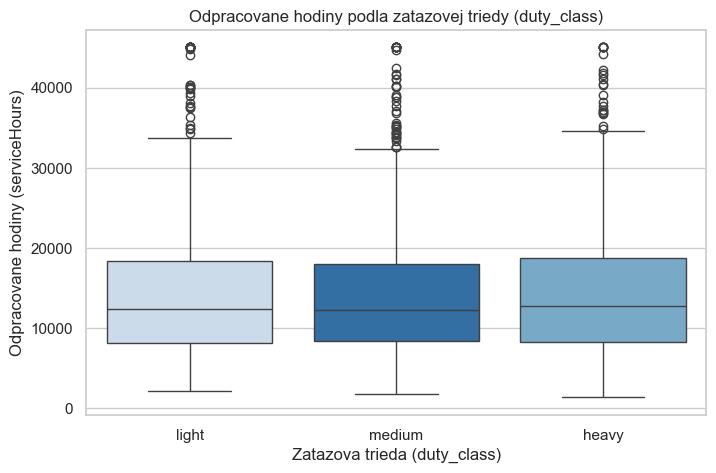

In [29]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=data_3,
    hue='duty_class',
    x='duty_class',
    y='serviceHours',
    order=['light', 'medium', 'heavy'],
    palette='Blues'
)
plt.title('Odpracovane hodiny podla zatazovej triedy (duty_class)')
plt.xlabel('Zatazova trieda (duty_class)')
plt.ylabel('Odpracovane hodiny (serviceHours)')
plt.show()

In [30]:
stats_dc_sh = data_3.groupby('duty_class')['serviceHours'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).reindex(['light', 'medium', 'heavy']).round(1)

display(stats_dc_sh)

,count,mean,median,std,min,max
duty_class,,,,,,
light,765,14497.9,12310.5,8837.3,2102.1,45000.0
medium,649,14536.4,12222.9,9043.7,1778.7,45000.0
heavy,486,14801.2,12718.2,9027.7,1303.0,45000.0


### duty_class vs. serviceHours

* Vyssi pocet hodin pri tazsej prevadzke: Stroje v triede heavy dosahuju najvyssi median odpracovanych hodin v porovnani s triedami medium a light
* Intenzita vyuzitia: duty_class priamo urcuje, ako intenzivne a v akych podmienkach je stroj nasadeny
* Rozdelenie dat: Boxplot ukazuje posun celeho rozdelenia hodin smerom nahor s rastucou zatazou (light - medium - heavy)

Zaver: Medzi zatazovou triedou a poctom odpracovanych hodin existuje zavislost - zataz stroja determinovala jeho celkovo nabehane hodiny

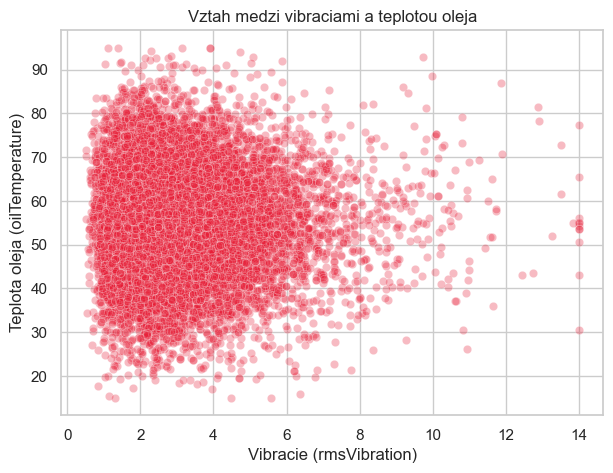

In [31]:
# Osetrenie chybnych hodnot (napriklad -999) pred vykreslenim
data_2['oilTemp_clean'] = data_2['oilTemperature'].replace(-999, np.nan)

# graf zavislosti
plt.figure(figsize=(7, 5))
sns.scatterplot(data=data_2, x='rmsVibration', y='oilTemp_clean', alpha=0.3, color='#e71d36')
plt.title('Vztah medzi vibraciami a teplotou oleja')
plt.xlabel('Vibracie (rmsVibration)')
plt.ylabel('Teplota oleja (oilTemperature)')
plt.show()

In [32]:
corr_oil_vib = data_2[['oilTemp_clean', 'rmsVibration']].corr().round(1)
display(corr_oil_vib)

,oilTemp_clean,rmsVibration
oilTemp_clean,1.0,-0.0
rmsVibration,-0.0,1.0


### oilTemperature vs. rmsVibration

* Korelacny koeficient: r = 0.0
* Rozlozenie bodov: Po odstraneni chybnych hodnot su body rovnomerne rozptylene

Zaver: Napriek ocakavanej zavislosti medzi vibraciami a teplotou motoroveho oleja sa v datach nezistil ziadny vztah - zrejme ide o nezavisle nasnimane parametre

## Parova analyza predikovanej premennej

### Zavislosti predikovanej premennej (Failure vs. Prediktory)
- **Failure vs. dp_filter** – Vplyv zaneseneho filtra na vznik poruchy
- **Failure vs. serviceHours** – Vplyv opotrebovania stroja na poruchovost

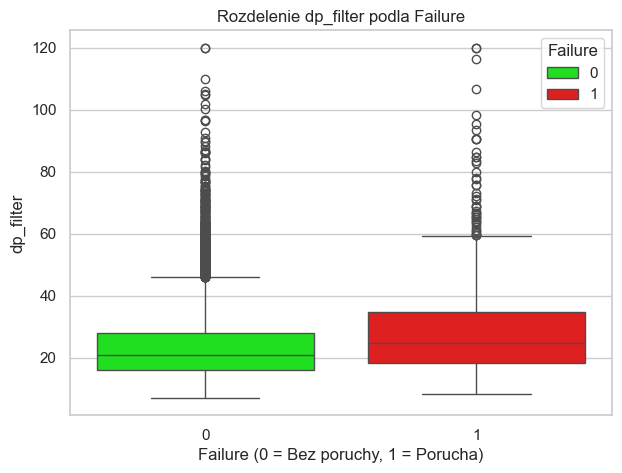

In [33]:
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=data_2,
    x='Failure',
    y='dp_filter',
    hue='Failure',
    palette=["#00FF00", '#ff0000']
)
plt.title('Rozdelenie dp_filter podla Failure')
plt.xlabel('Failure (0 = Bez poruchy, 1 = Porucha)')
plt.ylabel('dp_filter')
plt.show()

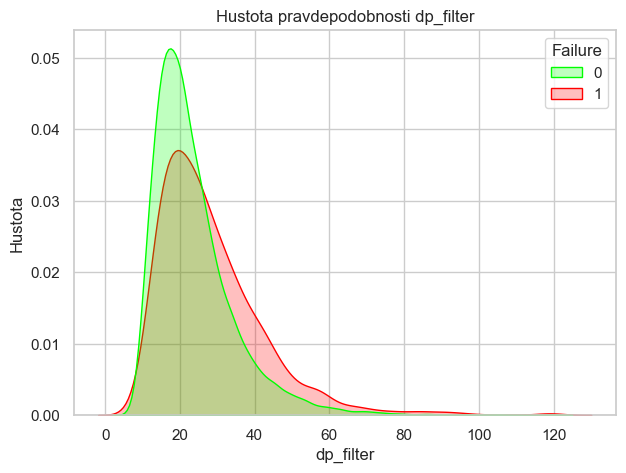

In [34]:
plt.figure(figsize=(7, 5))
sns.kdeplot(
    data=data_2,
    x='dp_filter',
    hue='Failure',
    common_norm=False,
    fill=True,
    palette=['#00FF00', '#ff0000']
)
plt.title('Hustota pravdepodobnosti dp_filter')
plt.xlabel('dp_filter')
plt.ylabel('Hustota')
plt.show()

In [35]:
stats_dp = data_2.groupby('Failure')['dp_filter'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(1)
display(stats_dp)

,count,mean,median,std,min,max
Failure,,,,,,
0,12142,23.6,21.0,11.0,7.1,120.0
1,1361,28.4,24.9,14.3,8.2,120.0


* Vyssie hodnoty pri poruche: Pri zlyhani stroja je median dp_filter vyssi (24.904) v porovnani s beznou prevadzkou (20.953). Rovnako stupa priemer z 23.588 na 28.403
* Rozdelenie dat: Graf hustoty aj boxplot ukazuju posun rozdelenia doprava smerom k vyssim hodnotam pri poruchovych stavoch
* Variabilita: Pri poruche je sledovana aj vyssia smerodajna odchylka (14.274 vs 10.966), co znaci vacsiu nestabilitu tlaku na filtri

Medzi dp_filter a Failure existuje pozitivna zavislost. Zvyseny tlakovy spad indikuje zanesenie filtra, co priamo zvysuje riziko poruchy stroja

In [36]:
# prepojenie tabuliek data_2 a data_3 cez id_unit
data_2['id_unit_num'] = data_2['id_unit'].str[1:].astype(int)
df_merged = data_2.merge(data_3, left_on='id_unit_num', right_index=True)

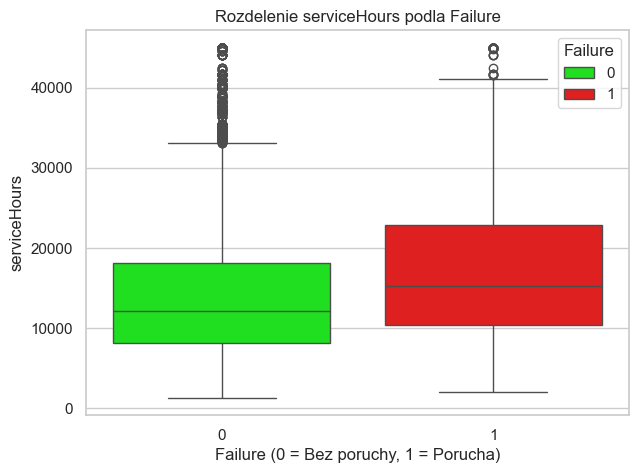

In [37]:
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df_merged,
    x='Failure',
    y='serviceHours',
    hue='Failure',
    palette=['#00FF00', '#ff0000']
)
plt.title('Rozdelenie serviceHours podla Failure')
plt.xlabel('Failure (0 = Bez poruchy, 1 = Porucha)')
plt.ylabel('serviceHours')
plt.show()

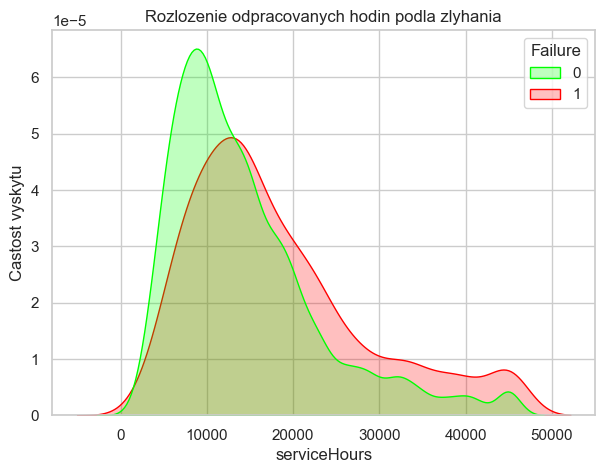

In [38]:
plt.figure(figsize=(7, 5))
sns.kdeplot(
    data=df_merged,
    x='serviceHours',
    hue='Failure',
    common_norm=False,
    fill=True,
    palette=['#00FF00', '#ff0000']
)
plt.title('Rozlozenie odpracovanych hodin podla zlyhania')
plt.xlabel('serviceHours')
plt.ylabel('Castost vyskytu')
plt.show()

In [39]:
stats_sh = df_merged.groupby('Failure')['serviceHours'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(1)
display(stats_sh)

,count,mean,median,std,min,max
Failure,,,,,,
0,11657,14321.6,12167.1,8724.4,1303.0,45000.0
1,1588,18150.2,15211.6,10372.9,2078.5,45000.0


* Vyssi pocet odpracovanych hodin pri poruche: Pri zlyhani stroja je median serviceHours vyssi (15211.6) v porovnani s beznou prevadzkou (12167.1). Priemer stupa z 14321.6 na 18150.2 hodin
* Rozdelenie dat: Graf hustoty ukazuje, ze pri vyssom pocte odpracovanych hodin (nad ~15 000 h) sa podiel poruch vyrazne zvysuje
* Variabilita: Smerodajna odchylka je pri poruchovych stavoch vyssia (10372.913 vs 8724.430), co ukazuje na roznorody vek kaziacich sa strojov

Medzi serviceHours a Failure existuje pozitivna zavislost. Pouzivanie stroja priamo zvysuje pravdepodobnost poruchy

## 1.2 Identifikácia problémov, integrácia a čistenie dát
geteways: 
- Inconsistant naming of the attributes for example: seen_last, Lon, versionFirmware, Technician - [x]
- gateway_id - bad format, shold be integer, not string [x]
- seen_last	- not consistant time format [x] 
- install_date - not consistant time format [x]
- id_unit	- only 2000 samples have it other 14000 have NaN; should be integer, not float [ ]

readings:
- Inconsistant naming of the attributes [ ] 
- id_unit - wrong format, shold be integer, not string [ ]
- cycle_ts - not consistant time format [ ]
- dp_filter and rmsVibration have NaN values  [ ]
- oilTemperature - min is -999.000000, not logical, problem in data [ ]

units: 
- Inconsistant naming of the attributes [ ]
- duty_class has inconsistant naming of categories 20, should be 3 ['light', 'heavy', 'medium'] [ ]
- overhaul_last - not consistant time format [ ]
- serviceHours - has 100 NaN values [ ]

In [33]:
data_1 = pd.read_csv(filename_1, 
                   sep=';', index_col=13)
data_1.head()

,seen_last,install_date,Lon,idDepot,macAddress,versionFirmware,signal_dbm,lat,Vendor,hardware_model,id_unit,Technician,ipv4
gateway_id,,,,,,,,,,,,,
GW-00000,2024-04-08,"10/03/2023, 00:00:00",-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
GW-00001,"11/07/2024, 00:00:00","07/11/2016, 00:00:00",-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
GW-00002,"10/02/2024, 00:00:00","05/04/2016, 00:00:00",-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
GW-00003,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
GW-00004,03 Aug 2024,2024/03/14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90


In [34]:
data_1 = data_1.rename({'Lon' : 'lon', 'idDeport' :'id_deport', 'versionFirmware' : 'version_firmware', 'Vendor' : 'vendor', 'Technician' : 'technician'}, axis='columns')
data_1.head()

,seen_last,install_date,lon,idDepot,macAddress,version_firmware,signal_dbm,lat,vendor,hardware_model,id_unit,technician,ipv4
gateway_id,,,,,,,,,,,,,
GW-00000,2024-04-08,"10/03/2023, 00:00:00",-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
GW-00001,"11/07/2024, 00:00:00","07/11/2016, 00:00:00",-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
GW-00002,"10/02/2024, 00:00:00","05/04/2016, 00:00:00",-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
GW-00003,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
GW-00004,03 Aug 2024,2024/03/14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90


In [35]:
data_1.index = data_1.index.str[3:].astype(int)
data_1.index.name = "gateway_id"

In [36]:
data_1.seen_last.head(50)

gateway_id
0               2024-04-08
1     11/07/2024, 00:00:00
2     10/02/2024, 00:00:00
3               2025-01-24
4              03 Aug 2024
5     10/20/2024, 00:00:00
6               2024-08-10
7               2024/04/24
8     12/25/2024, 00:00:00
9     04/03/2024, 00:00:00
10             16 Oct 2024
11    06/19/2024, 00:00:00
12              2024-04-13
13    10/12/2024, 00:00:00
14              2024-08-01
15    10/28/2024, 00:00:00
16              2024/12/10
17              2024-11-01
18              2024/04/11
19              2025-01-02
20             12 May 2024
21             28 Jan 2024
22              2024-02-14
23              2024-04-26
24              2024-09-29
25             22 Aug 2024
26             29 Jan 2025
27              2024/03/12
28              2024-05-08
29              2024-12-07
30             10 Oct 2024
31              2024-07-24
32             02 Sep 2024
33             06 Nov 2024
34              2024-06-12
35    02/19/2024, 00:00:00
36    03/27/2024,

In [37]:
formats = ["%Y-%m-%d", "%Y/%m/%d", "%d %b %Y", "%m/%d/%Y, %H:%M:%S"]

def parse_dates(col):
    s = col.astype(str).str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in formats:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

for c in ["install_date", "seen_last"]:
    data_1[c] = parse_dates(data_1[c])

In [38]:
s = data_1["install_date"].astype(str).str.strip()
print(s[parse_dates(s).isna()])

Series([], Name: install_date, dtype: str)


In [39]:
s = data_1["seen_last"].astype(str).str.strip()
print(s[parse_dates(s).isna()])

Series([], Name: seen_last, dtype: str)


In [40]:
data_1["install_date"] = data_1["install_date"].dt.strftime("%Y-%m-%d")

In [41]:
data_1["seen_last"] = data_1["seen_last"].dt.strftime("%Y-%m-%d")

In [42]:
data_1.head()   

,seen_last,install_date,lon,idDepot,macAddress,version_firmware,signal_dbm,lat,vendor,hardware_model,id_unit,technician,ipv4
gateway_id,,,,,,,,,,,,,
0,2024-04-08,2023-10-03,-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831.0,Elenore Herrmann,67.49.73.170
1,2024-11-07,2016-07-11,-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488.0,Bradley Fleming,16.98.36.57
2,2024-10-02,2016-05-04,-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231.0,Sofia Loureiro,80.107.147.21
3,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396.0,Michael Navarro,216.20.189.94
4,2024-08-03,2024-03-14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502.0,Ivan Branco,248.247.103.90


In [45]:
data_1["id_unit"] = data_1["id_unit"].astype("Int64")
data_1.head()

,seen_last,install_date,lon,idDepot,macAddress,version_firmware,signal_dbm,lat,vendor,hardware_model,id_unit,technician,ipv4
gateway_id,,,,,,,,,,,,,
0,2024-04-08,2023-10-03,-8.89921,112,e2:f9:05:83:4d:20,v2.7.0,-66.2,38.91850,Fritsch,GWX-200,1831,Elenore Herrmann,67.49.73.170
1,2024-11-07,2016-07-11,-7.87246,88,6d:a5:2b:72:5b:10,v1.2.5,-75.7,39.79636,Nogueira,GWX-100,488,Bradley Fleming,16.98.36.57
2,2024-10-02,2016-05-04,-8.66738,85,ac:73:9a:fb:a3:73,v1.2.5,-71.4,38.82073,Leite,NODE-7,231,Sofia Loureiro,80.107.147.21
3,2025-01-24,2018-08-29,-6.64779,116,0f:21:99:19:d3:cb,v1.2.5,-76.6,41.01462,Speer,GWX-100,396,Michael Navarro,216.20.189.94
4,2024-08-03,2024-03-14,-8.80419,26,a7:13:08:aa:79:70,v2.7.0,-59.8,38.86962,Paiva Leite Lda.,NODE-9,1502,Ivan Branco,248.247.103.90


In [47]:
data_1.to_csv("./data/Ciste_data/data_1_clean.csv")